# Nº 10 · Minimums locaux et points selle

*θ Théta, le Machine Learning, une notion à la fois.*

Une pente nulle ne dit pas ce que l'on a trouvé. On construit les trois cas : un minimum local, un point selle et
une fonction convexe.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Le premier creux

La courbe f(x) = x·cos(πx), reprise de D2L 12.1, a deux creux sur cet intervalle. La descente reste dans celui
où elle commence.

à gauche : arrêt en x = -0.274, J = -0.179
à droite : arrêt en x = 1.090, J = -1.047


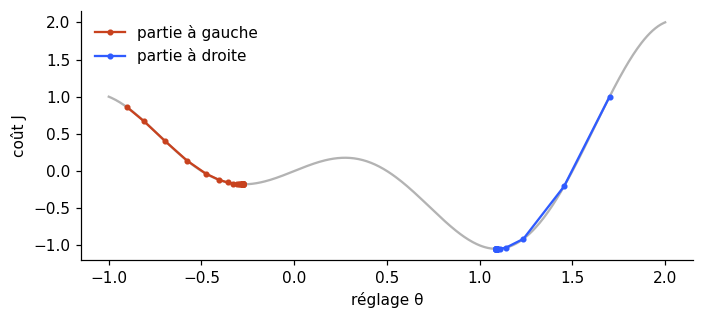

In [2]:
def f(x):
    return x * np.cos(np.pi * x)


def pente_f(x):
    return np.cos(np.pi * x) - np.pi * x * np.sin(np.pi * x)


def descendre(depart, eta=0.05, pas=60):
    chemin = [depart]
    for _ in range(pas):
        chemin.append(chemin[-1] - eta * pente_f(chemin[-1]))
    return np.array(chemin)


grille = np.linspace(-1, 2, 400)
a_gauche, a_droite = descendre(-0.9), descendre(1.7)

plt.figure(figsize=(6.5, 3))
plt.plot(grille, f(grille), color="0.7")
plt.plot(a_gauche, f(a_gauche), "o-", color="#C8421E", markersize=3, label="partie à gauche")
plt.plot(a_droite, f(a_droite), "o-", color="#2F5BFF", markersize=3, label="partie à droite")
plt.xlabel("réglage θ")
plt.ylabel("coût J")
plt.legend(frameon=False)
plt.tight_layout()

print(f"à gauche : arrêt en x = {a_gauche[-1]:.3f}, J = {f(a_gauche[-1]):.3f}")
print(f"à droite : arrêt en x = {a_droite[-1]:.3f}, J = {f(a_droite[-1]):.3f}")
assert abs(pente_f(a_gauche[-1])) < 1e-3 and abs(pente_f(a_droite[-1])) < 1e-3
assert f(a_droite[-1]) < f(a_gauche[-1])  # même pente nulle, mais un creux plus bas

Les deux descentes finissent avec une pente nulle. Seule celle de droite trouve le minimum global.

## 2. Le point selle

Pour J(a, b) = a² − b², le gradient (2a ; −2b) s'annule en (0 ; 0). Ce point est un creux selon a, une bosse selon b.

In [3]:
def descente_selle(depart, eta=0.1, pas=40):
    chemin = [np.array(depart, dtype=float)]
    for _ in range(pas):
        a, b = chemin[-1]
        chemin.append(chemin[-1] - eta * np.array([2 * a, -2 * b]))
    return np.array(chemin)


sur_axe = descente_selle([-2.2, 0])
a_cote = descente_selle([-2.2, 0.08])
print("partie sur l'axe :", np.round(sur_axe[-1], 4))
print("partie à côté    :", np.round(a_cote[-1], 1))
assert np.linalg.norm(sur_axe[-1]) < 1e-2  # cale au point selle
assert abs(a_cote[-1, 1]) > 1  # s'en écarte

partie sur l'axe : [-0.0003  0.    ]
partie à côté    : [ -0.  117.6]


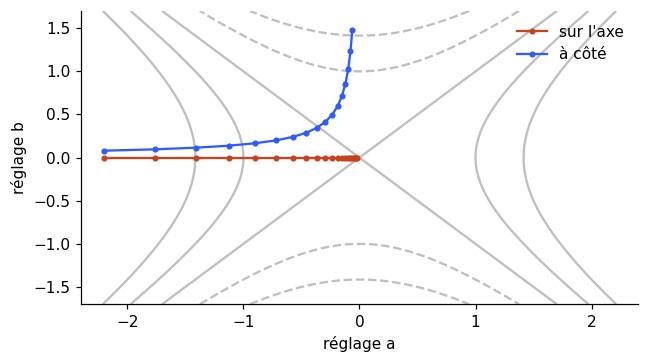

In [4]:
A, B = np.meshgrid(np.linspace(-2.4, 2.4, 200), np.linspace(-1.7, 1.7, 200))
plt.figure(figsize=(6, 3.4))
plt.contour(A, B, A**2 - B**2, levels=[-2, -1, 0, 1, 2], colors="0.75")
plt.plot(*sur_axe[:21].T, "o-", color="#C8421E", markersize=3, label="sur l'axe")
visible = a_cote[np.abs(a_cote[:, 1]) < 1.7]
plt.plot(*visible.T, "o-", color="#2F5BFF", markersize=3, label="à côté")
plt.xlabel("réglage a")
plt.ylabel("réglage b")
plt.legend(frameon=False)
plt.tight_layout()

## 3. Reconnaître le point : les courbures

La matrice des dérivées secondes (hessienne) tranche : valeurs propres toutes positives pour un minimum, de signes
mélangés pour un point selle.

In [5]:
print("J = a² + b² :", np.linalg.eigvalsh(np.diag([2.0, 2.0])))
print("J = a² − b² :", np.linalg.eigvalsh(np.diag([2.0, -2.0])))
assert (np.linalg.eigvalsh(np.diag([2.0, -2.0])) * [1, -1] < 0).all()

J = a² + b² : [2. 2.]
J = a² − b² : [-2.  2.]


## 4. Une fonction convexe : pas de faux creux

Toute corde reste au-dessus de la courbe, et tout minimum local est global. C'est le cas de la MSE d'une droite.

In [6]:
rng = np.random.default_rng(0)
g = lambda x: x**2
paires = rng.uniform(-3, 3, (500, 2))
poids = rng.uniform(0, 1, 500)
corde = poids * g(paires[:, 0]) + (1 - poids) * g(paires[:, 1])
courbe = g(poids * paires[:, 0] + (1 - poids) * paires[:, 1])
print("corde au-dessus de la courbe sur 500 tirages :", bool((corde >= courbe - 1e-12).all()))
assert (corde >= courbe - 1e-12).all()

corde au-dessus de la courbe sur 500 tirages : True


## À vous

1. Sur f(x) = x·cos(πx), cherchez les départs qui mènent au minimum global.
2. Partez à (−2,2 ; 1e-6) sur le point selle : combien de pas pour s'en écarter ?

**Sources** : D2L 12.1 et 12.2, Machine Learning Crash Course, Dauphin et al. (2014).